<a href="https://colab.research.google.com/github/elfrontman/assesment3_is/blob/heidy-hf-preprocessing/notebooks/02_preprocessing_huggingface.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# ISY503 — Assessment 3: Data Preprocessing & Hugging Face Tokenization

**Project:** NLP Sentiment Analysis on Amazon Product Reviews  
**Notebook:** 02_preprocessing_huggingface.ipynb  
**Branch:** heidy-hf-preprocessing  
**Owner:** Heidy

## Objective

This notebook covers Steps 4–6 of the team workflow: Train / Validation / Test splitting, Hugging Face GPT-2 tokenization, padding and truncation, and dataset preparation for model training.

The objective is to transform the cleaned Amazon product reviews into structured inputs that can be directly used during GPT-2 fine-tuning.

**Core question:**

How can we prepare the Amazon reviews for GPT-2 while preserving sentiment labels, preventing data leakage, and ensuring compatibility with Hugging Face?


## 0. Install Required Libraries

Install the Python libraries required for data preprocessing, GPT-2 tokenization and Hugging Face dataset preparation.

These libraries will also support the next stage of the project, including model training and fine-tuning.

In [ ]:
# Install the libraries required for preprocessing and GPT-2

%pip install -q transformers datasets scikit-learn





## 1. Setup & Configuration

Import the required libraries and configure reproducibility, file paths and project settings.

Google Colab will be used as the development environment. The repository will be accessed through GitHub.

In [ ]:

# Connect Google Colab to the project repository

import subprocess
from pathlib import Path

REPO_ROOT = Path("/content/assesment3_is")

if not REPO_ROOT.exists():
    subprocess.run(
        [
            "git",
            "clone",
            "--branch",
            "heidy-hf-preprocessing",
            "https://github.com/elfrontman/assesment3_is.git",
            str(REPO_ROOT)
        ],
        check=True
    )

print("Repository location:", REPO_ROOT)
print("Repository exists:", REPO_ROOT.exists())

Repository location: /content/assesment3_is
Repository exists: True


In [ ]:
# Import required libraries

import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from transformers import GPT2TokenizerFast
from datasets import Dataset, DatasetDict

from sklearn.model_selection import train_test_split


# Reproducibility
RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)


# Project configuration
MODEL_NAME = "gpt2"

TRAIN_SIZE = 0.70
VALIDATION_SIZE = 0.15
TEST_SIZE = 0.15

assert TRAIN_SIZE + VALIDATION_SIZE + TEST_SIZE == 1.0


# Repository paths
REPO_ROOT = Path("/content/assesment3_is")

PROCESSED_DIR = REPO_ROOT / "data" / "processed"

OUTPUT_DIR = REPO_ROOT / "outputs" / "preprocessing"

SPLIT_DIR = OUTPUT_DIR / "splits"

TOKENIZED_DIR = OUTPUT_DIR / "tokenized_dataset"


# Create output directories
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
TOKENIZED_DIR.mkdir(parents=True, exist_ok=True)


# Input dataset
DATA_FILE = PROCESSED_DIR / "amazon_reviews_no_duplicates.csv"


# Verify project paths
print("=" * 55)
print("PROJECT CONFIGURATION")
print("=" * 55)

print(f"Repository root: {REPO_ROOT}")
print(f"Processed data: {PROCESSED_DIR}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Input dataset: {DATA_FILE}")
print(f"Model: {MODEL_NAME}")

print("\nEnvironment information:")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")


# Validate input dataset
assert REPO_ROOT.exists(), "Repository directory not found."
assert DATA_FILE.exists(), f"Dataset not found: {DATA_FILE}"

print("\nRepository and input dataset verified successfully.")

PROJECT CONFIGURATION
Repository root: /content/assesment3_is
Processed data: /content/assesment3_is/data/processed
Output directory: /content/assesment3_is/outputs/preprocessing
Input dataset: /content/assesment3_is/data/processed/amazon_reviews_no_duplicates.csv
Model: gpt2

Environment information:
PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4

Repository and input dataset verified successfully.



### 1.2 Environment Verification

Before proceeding with the preprocessing workflow, we verify that the required libraries have been imported successfully.

Checking the installed versions helps maintain reproducibility and identify potential compatibility issues during development.


In [ ]:

# Verify required libraries

import transformers
import datasets
import sklearn
import torch

print("Transformers version:", transformers.__version__)
print("Datasets version:", datasets.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("PyTorch version:", torch.__version__)

print("\nAll required libraries imported successfully.")


Transformers version: 5.22.1
Datasets version: 4.8.5
Scikit-learn version: 1.6.1
PyTorch version: 2.14.1+cu130

All required libraries imported successfully.


# 2. Data Loading & Initial Inspection

This section loads the cleaned and deduplicated Amazon reviews dataset prepared by Carlos during the Data Loading and Exploratory Data Analysis (EDA) stage.

The purpose is to verify the dataset structure, identify the available columns, inspect the sentiment labels, and confirm that the data is ready for preprocessing.

The dataset contains 7,852 unique labeled reviews across four Amazon product domains:

Books
DVD
Electronics
Kitchen & Housewares

The following checks will be performed:

Load the processed CSV file.
Inspect the dataset dimensions and column names.
Display the first five records.
Check data types and missing values.
Examine sentiment labels and domain distributions.

Important: The original dataset prepared by Carlos will remain unchanged. This stage focuses on inspection before splitting the data into training, validation, and test sets.

In [ ]:
# Load processed Amazon reviews dataset

df = pd.read_csv(DATA_FILE)

print("=" * 55)
print("DATASET LOADING")
print("=" * 55)

print(f"Total reviews loaded: {len(df):,}")

print("\nDataset columns:")
print(df.columns.tolist())

print("\nDataset shape:")
print(df.shape)

print("\nFirst five records:")
display(df.head())

DATASET LOADING
Total reviews loaded: 7,852

Dataset columns:
['review_id', 'domain', 'sentiment', 'label', 'title_clean', 'review_text_clean', 'full_text']

Dataset shape:
(7852, 7)

First five records:


,review_id,domain,sentiment,label,title_clean,review_text_clean,full_text
0,0,books,positive,1,One of the best Crichton novels,Sphere by Michael Crichton is an excellant nov...,One of the best Crichton novels. Sphere by Mic...
1,1,books,positive,1,The Medicine of the Future,Dr. Oz is an accomplished heart surgeon in the...,The Medicine of the Future. Dr. Oz is an accom...
2,2,books,positive,1,Beautiful!,The most gorgeous artwork in comic books. Cont...,Beautiful!. The most gorgeous artwork in comic...
3,3,books,positive,1,For lovers of Robicheaux,This book is for lovers of Robicheaux. His dem...,For lovers of Robicheaux. This book is for lov...
4,4,books,positive,1,Excellent and broad survey of the development ...,This is going to be a short and sweet review b...,Excellent and broad survey of the development ...


# 3. Train / Validation / Test Split

Before applying GPT-2 tokenization, the dataset will be divided into three independent subsets: Training, Validation, and Test.

The selected proportions are:

Training: 70% – used to train the model.

Validation: 15% – used to monitor model performance and support model selection and hyperparameter tuning.

Test: 15% – reserved for the final evaluation of the trained model.

Stratification Strategy

A stratified splitting approach will be applied using both domain and label.

This decision aims to preserve the distribution of the four product domains (Books, DVD, Electronics, and Kitchen & Housewares) and both sentiment classes (positive and negative) across all three subsets.

The combined domain and label values will be used to create stratification groups. This helps ensure that each subset maintains a representative distribution of the original dataset.

Data Leakage Prevention

The test set will remain completely separate from the training and validation processes. It will not be used for model training, hyperparameter tuning, or model selection.

The same random seed (RANDOM_STATE = 42) will be maintained to ensure reproducibility.

The resulting datasets will be prepared for the next stage: GPT-2 tokenization and input preparation.

In [ ]:
# Create stratification groups using domain and sentiment label

df["stratify_group"] = (
    df["domain"].astype(str) + "_" + df["label"].astype(str)
)


# First split: 70% training and 30% temporary data

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=df["stratify_group"]
)


# Second split: 15% validation and 15% test

validation_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=temp_df["stratify_group"]
)


# Reset indexes

train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)


# Display split sizes

print("=" * 55)
print("TRAIN / VALIDATION / TEST SPLIT")
print("=" * 55)

print(f"Training reviews:   {len(train_df):,}")
print(f"Validation reviews: {len(validation_df):,}")
print(f"Test reviews:       {len(test_df):,}")

print(f"\nTotal reviews:      {len(train_df) + len(validation_df) + len(test_df):,}")

TRAIN / VALIDATION / TEST SPLIT
Training reviews:   5,496
Validation reviews: 1,178
Test reviews:       1,178

Total reviews:      7,852


# 3.1 Verification of Stratified Split Distribution
After creating the Training, Validation, and Test subsets, the stratification results must be verified to ensure that the original distribution of product domains and sentiment labels has been preserved.

This verification checks:

The number of positive and negative reviews within each product domain.
The percentage distribution of sentiment classes across each subset.
The consistency of the domain and sentiment representation across Training, Validation, and Test.
Expected outcome: All three subsets should maintain approximately the same distribution of domains and sentiment classes as the original dataset.

This step helps ensure that the model is trained and evaluated using representative data, reducing the risk of biased evaluation results.

In [ ]:
# Verify domain and sentiment distribution across splits

print("=" * 55)
print("STRATIFIED SPLIT DISTRIBUTION")
print("=" * 55)

for split_name, split_df in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:
    print(f"\n{split_name} distribution:")

    distribution = pd.crosstab(
        split_df["domain"],
        split_df["sentiment"]
    )

    display(distribution)

    print("\nPercentage distribution:")
    display(
        pd.crosstab(
            split_df["domain"],
            split_df["sentiment"],
            normalize="all"
        ).round(4) * 100
    )

STRATIFIED SPLIT DISTRIBUTION

Training distribution:


sentiment,negative,positive
domain,,
books,674,695
dvd,671,696
electronics,685,691
kitchen_&_housewares,687,697



Percentage distribution:


sentiment,negative,positive
domain,,
books,12.26,12.65
dvd,12.21,12.66
electronics,12.46,12.57
kitchen_&_housewares,12.50,12.68



Validation distribution:


sentiment,negative,positive
domain,,
books,144,149
dvd,144,150
electronics,146,148
kitchen_&_housewares,147,150


... (2 outputs left out)


Test distribution:


sentiment,negative,positive
domain,,
books,145,149
dvd,144,149
electronics,147,148
kitchen_&_housewares,147,149



Percentage distribution:


sentiment,negative,positive
domain,,
books,12.31,12.65
dvd,12.22,12.65
electronics,12.48,12.56
kitchen_&_housewares,12.48,12.65


#3.2 Saving the Data Splits

After verifying the stratified distribution, the three datasets will be saved as separate CSV files.

The following files will be generated:

train.csv: Training data (70%).
validation.csv: Validation data (15%).
test.csv: Test data (15%).

The files will be stored in outputs/preprocessing/splits/ to ensure that the next project stages can access the same data splits.

The temporary stratify_group column will be removed because it was only required for the stratification process.

Important: The test dataset will remain separate and must not be used during model training or hyperparameter tuning.

Saving these datasets ensures reproducibility and provides with consistent inputs for the GPT-2 fine-tuning stage.

In [ ]:
# Save train, validation and test datasets

# Remove temporary stratification column
columns_to_save = [
    "review_id",
    "domain",
    "sentiment",
    "label",
    "title_clean",
    "review_text_clean",
    "full_text"
]

train_df[columns_to_save].to_csv(
    SPLIT_DIR / "train.csv",
    index=False
)

validation_df[columns_to_save].to_csv(
    SPLIT_DIR / "validation.csv",
    index=False
)

test_df[columns_to_save].to_csv(
    SPLIT_DIR / "test.csv",
    index=False
)


# Verify saved files

print("=" * 55)
print("DATA SPLITS SAVED SUCCESSFULLY")
print("=" * 55)

for file_name in ["train.csv", "validation.csv", "test.csv"]:
    file_path = SPLIT_DIR / file_name
    saved_df = pd.read_csv(file_path)

    print(f"\nFile: {file_name}")
    print(f"Path: {file_path}")
    print(f"Rows: {len(saved_df):,}")
    print(f"Columns: {len(saved_df.columns)}")
    print(f"File exists: {file_path.exists()}")

DATA SPLITS SAVED SUCCESSFULLY

File: train.csv
Path: /content/assesment3_is/outputs/preprocessing/splits/train.csv
Rows: 5,496
Columns: 7
File exists: True

File: validation.csv
Path: /content/assesment3_is/outputs/preprocessing/splits/validation.csv
Rows: 1,178
Columns: 7
File exists: True

File: test.csv
Path: /content/assesment3_is/outputs/preprocessing/splits/test.csv
Rows: 1,178
Columns: 7
File exists: True


## 4. GPT-2 Tokenizer Configuration

After completing the dataset splitting process, the next stage is to configure the GPT-2 tokenizer using the Hugging Face Transformers library.

GPT-2 uses Byte Pair Encoding (BPE), a subword tokenization method that converts text into numerical token IDs that can be processed by the model.

This section will:

- Load the previously saved Training, Validation and Test datasets.
- Download and configure the GPT-2 tokenizer.
- Configure a padding token, since GPT-2 does not include one by default.
- Analyse the number of tokens generated by the reviews.
- Determine an appropriate maximum sequence length based on the training data.

The same tokenizer configuration will be applied consistently across all three datasets.

Importantly, the Test dataset will not be used to determine preprocessing parameters.

In [15]:

# Load the three previously saved datasets

train_df = pd.read_csv(SPLIT_DIR / "train.csv")
validation_df = pd.read_csv(SPLIT_DIR / "validation.csv")
test_df = pd.read_csv(SPLIT_DIR / "test.csv")

print("=" * 55)
print("SAVED DATASETS LOADED")
print("=" * 55)

for name, dataset in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:
    print(f"{name}: {len(dataset):,} reviews")

print("\nTotal reviews:",
      len(train_df) + len(validation_df) + len(test_df))

# Verify required columns
required_columns = ["full_text", "label"]

for name, dataset in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:
    assert all(col in dataset.columns for col in required_columns)
    assert dataset["full_text"].notna().all()
    assert dataset["label"].isin([0, 1]).all()

print("\nAll datasets passed the initial validation.")


SAVED DATASETS LOADED
Training: 5,496 reviews
Validation: 1,178 reviews
Test: 1,178 reviews

Total reviews: 7852

All datasets passed the initial validation.



### 4.2 Download and Configure GPT-2 Tokenizer

The GPT-2 tokenizer will be downloaded from Hugging Face using the pretrained model identifier `gpt2`.

GPT-2 uses Byte Pair Encoding (BPE) to split text into subword units rather than treating every complete word as a single token.

Unlike some other Transformer tokenizers, GPT-2 does not provide a dedicated padding token by default.

To address this, the End-of-Sequence (EOS) token will be reused as the padding token. This allows reviews of different lengths to be processed consistently during model training.

The tokenizer will also use right-side padding, ensuring that padding tokens are added after the original review text.


In [16]:

# Download GPT-2 tokenizer

tokenizer = GPT2TokenizerFast.from_pretrained(MODEL_NAME)

# Configure padding token
tokenizer.pad_token = tokenizer.eos_token

# Configure padding direction
tokenizer.padding_side = "right"

print("=" * 55)
print("GPT-2 TOKENIZER CONFIGURATION")
print("=" * 55)

print("Model:", MODEL_NAME)
print("Tokenizer:", tokenizer.__class__.__name__)
print("Vocabulary size:", tokenizer.vocab_size)
print("EOS token:", tokenizer.eos_token)
print("EOS token ID:", tokenizer.eos_token_id)
print("PAD token:", tokenizer.pad_token)
print("PAD token ID:", tokenizer.pad_token_id)
print("Padding side:", tokenizer.padding_side)
print("Model maximum positions:", tokenizer.model_max_length)

# Verify configuration
assert tokenizer.pad_token_id is not None
assert tokenizer.padding_side == "right"

print("\nGPT-2 tokenizer configured successfully.")


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

GPT-2 TOKENIZER CONFIGURATION
Model: gpt2
Tokenizer: GPT2Tokenizer
Vocabulary size: 50257
EOS token: <|endoftext|>
EOS token ID: 50256
PAD token: <|endoftext|>
PAD token ID: 50256
Padding side: right
Model maximum positions: 1024

GPT-2 tokenizer configured successfully.



### 4.3 Analysis of GPT-2 Tokenization and Sequence Lengths

Before applying tokenization to the complete datasets, we will examine how GPT-2 converts Amazon reviews into tokens.

The analysis will focus on:

- Comparing original text with its tokenized representation.
- Understanding how words are divided into subword tokens.
- Measuring the number of tokens generated by each review.
- Examining sequence length percentiles.

The 95th percentile of the Training dataset will be used as a reference when selecting the maximum sequence length, with a maximum limit of 512 tokens for this preprocessing experiment.

This approach aims to retain most review content while controlling computational requirements.

The Validation and Test datasets will use exactly the same sequence length.


In [17]:

# Select an example review from the training dataset

sample_review = train_df["full_text"].iloc[0]

# Tokenize the example
sample_encoding = tokenizer(
    sample_review,
    add_special_tokens=True,
    truncation=False
)

sample_tokens = tokenizer.convert_ids_to_tokens(
    sample_encoding["input_ids"]
)

print("=" * 55)
print("GPT-2 TOKENIZATION EXAMPLE")
print("=" * 55)

print("\nOriginal review:")
print(sample_review)

print("\nNumber of tokens:", len(sample_tokens))

print("\nFirst 30 tokens:")
print(sample_tokens[:30])

print("\nFirst 30 token IDs:")
print(sample_encoding["input_ids"][:30])


GPT-2 TOKENIZATION EXAMPLE

Original review:
Repulsive. We have to do better than this for our children. Controlling and turning your kid into the perfect little, well behaved lemming is going to haunt you until you die. This type of abuse never has a good, long term effect on anyone. Put the paddles and belts down and talk to your kids. They deserve at least that much

Number of tokens: 73

First 30 tokens:
['Rep', 'ulsive', '.', 'ĠWe', 'Ġhave', 'Ġto', 'Ġdo', 'Ġbetter', 'Ġthan', 'Ġthis', 'Ġfor', 'Ġour', 'Ġchildren', '.', 'ĠCont', 'rolling', 'Ġand', 'Ġturning', 'Ġyour', 'Ġkid', 'Ġinto', 'Ġthe', 'Ġperfect', 'Ġlittle', ',', 'Ġwell', 'Ġbehaved', 'Ġle', 'm', 'ming']

First 30 token IDs:
[6207, 22220, 13, 775, 423, 284, 466, 1365, 621, 428, 329, 674, 1751, 13, 2345, 18886, 290, 6225, 534, 5141, 656, 262, 2818, 1310, 11, 880, 39207, 443, 76, 2229]



**Results and Interpretation**

The example demonstrates how GPT-2 applies Byte Pair Encoding (BPE) to Amazon review text.

The selected review generated 73 tokens. The token output shows that GPT-2 does not necessarily represent each word as a single token. For example, some words are divided into smaller subword units.

The `Ġ` character in the token representation indicates a preceding space. This is part of GPT-2's byte-level tokenization representation.

The resulting token IDs provide the numerical input required by the Transformer model.

This confirms that the tokenizer is correctly converting the original review text into GPT-2-compatible numerical representations.



### 4.3.1 Training Review Token Length Analysis

After examining an individual tokenization example, we will analyse the token lengths across the complete Training dataset.

This analysis measures how many GPT-2 tokens are generated for each review.

The following statistical measures will be examined:

- Minimum and maximum token length.
- Mean and median token length.
- 75th, 90th, 95th and 99th percentiles.

Only the Training dataset will be used to determine the sequence length distribution.

This is important because preprocessing decisions should not depend on the Test dataset, helping prevent data leakage.

The results will provide a quantitative basis for selecting an appropriate maximum sequence length while balancing information retention and computational efficiency.


In [18]:

# Analyse token lengths using Training data only

train_token_lengths = [
    len(tokenizer.encode(text, add_special_tokens=True))
    for text in train_df["full_text"]
]

length_stats = pd.Series(train_token_lengths).describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
)

print("=" * 55)
print("TRAINING TOKEN LENGTH ANALYSIS")
print("=" * 55)

display(length_stats)

print("\nToken length percentiles:")

for percentile in [50, 75, 90, 95, 99]:
    value = np.percentile(train_token_lengths, percentile)
    print(f"{percentile}th percentile: {value:.0f} tokens")


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1070 > 1024). Running this sequence through the model will result in indexing errors


TRAINING TOKEN LENGTH ANALYSIS


,0
count,5496.000000
mean,171.348617
std,187.340819
min,11.000000
50%,114.000000
75%,204.000000
90%,364.000000
95%,524.250000
99%,955.150000
max,4551.000000



Token length percentiles:
50th percentile: 114 tokens
75th percentile: 204 tokens
90th percentile: 364 tokens
95th percentile: 524 tokens
99th percentile: 955 tokens



**Results and Interpretation**

The Training dataset contains 5,496 reviews, with an average token length of approximately 171 tokens and a median of 114 tokens.

The distribution shows that most reviews are relatively short:

- 50% of reviews contain approximately 114 tokens or fewer.
- 75% contain approximately 204 tokens or fewer.
- 90% contain approximately 364 tokens or fewer.
- 95% contain approximately 524 tokens or fewer.

However, the maximum sequence length reaches 4,551 tokens, demonstrating that a small number of reviews are considerably longer than the majority.

The warning generated during token length analysis indicates that some sequences exceed GPT-2's default maximum position limit of 1,024 tokens. This does not indicate a preprocessing failure because these sequences are only being analysed, not passed directly into the model.

These findings support the need for a controlled maximum sequence length and truncation strategy.



### 4.3.2 Visualisation of Training Token Length Distribution

A histogram will be used to visualise the distribution of GPT-2 token lengths across the Training dataset.

The visualisation includes two reference lines:

- The 95th percentile, representing the token length below which approximately 95% of training reviews fall.
- The 512-token limit, representing the maximum sequence length considered for this experiment.

This visualisation helps identify the distribution of short and long reviews and understand the potential impact of truncation.

It will also support the decision regarding the maximum sequence length used in the subsequent preprocessing stages.


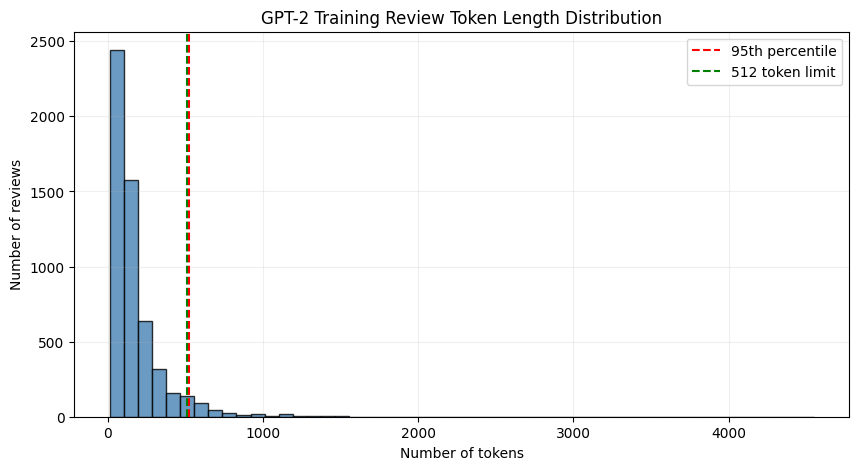

In [19]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    train_token_lengths,
    bins=50,
    color="steelblue",
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    np.percentile(train_token_lengths, 95),
    color="red",
    linestyle="--",
    label="95th percentile"
)

plt.axvline(
    512,
    color="green",
    linestyle="--",
    label="512 token limit"
)

plt.title("GPT-2 Training Review Token Length Distribution")
plt.xlabel("Number of tokens")
plt.ylabel("Number of reviews")
plt.legend()
plt.grid(alpha=0.2)

plt.show()



**Results and Interpretation**

The histogram shows a right-skewed distribution, with the highest concentration of reviews appearing in the lower token length ranges.

Approximately 2,500 reviews fall within the 0–100 token range, while around 1,600 reviews contain between 100 and 200 tokens.

The number of reviews progressively decreases as token length increases, creating a long right tail.

This indicates that most Amazon reviews are relatively short, although a smaller proportion contains substantially longer text.

The 95th percentile reference line highlights that approximately 5% of the Training reviews exceed this statistical threshold.

The visualisation supports selecting a maximum sequence length that balances information retention and computational efficiency.


### 4.3.3 Selection of Maximum Sequence Length

Based on the token length analysis, an appropriate maximum sequence length will be selected for GPT-2.

The 95th percentile of the Training dataset will be used as the statistical reference.

The selected value will be rounded up to the nearest multiple of eight to support efficient batch processing.

A maximum limit of 512 tokens will also be enforced to remain within the computational constraints of the experiment.

Reviews exceeding the selected maximum length will be truncated, while shorter reviews will retain their original token sequences until dynamic padding is applied.

The selected maximum sequence length will remain consistent across Training, Validation and Test datasets.

This decision aims to preserve most of the review information while maintaining computational efficiency during fine-tuning.

In [20]:

# Determine maximum sequence length

PERCENTILE = 95
MODEL_MAX_LENGTH = 512

percentile_length = int(
    np.ceil(np.percentile(train_token_lengths, PERCENTILE))
)

MAX_LENGTH = min(
    MODEL_MAX_LENGTH,
    max(8, int(np.ceil(percentile_length / 8) * 8))
)

print("=" * 55)
print("MAXIMUM SEQUENCE LENGTH")
print("=" * 55)

print(f"95th percentile: {percentile_length}")
print(f"Selected MAX_LENGTH: {MAX_LENGTH}")

print("\nThis value will be applied consistently")
print("to Training, Validation and Test datasets.")


MAXIMUM SEQUENCE LENGTH
95th percentile: 525
Selected MAX_LENGTH: 512

This value will be applied consistently
to Training, Validation and Test datasets.



**Results and Interpretation**

The 95th percentile of the Training token length distribution is approximately 524 tokens.

Following the predefined selection strategy, this value is rounded up to the nearest multiple of eight, resulting in 528 tokens.

However, the selected maximum sequence length is capped at 512 tokens to remain within the defined computational constraints.

Therefore, `MAX_LENGTH = 512` will be used consistently across Training, Validation and Test datasets.

Reviews exceeding this limit will be truncated, while shorter reviews will retain their original content.

This decision provides a practical balance between preserving review information and maintaining compatibility with the selected GPT-2 configuration.



## 5. Tokenization, Padding and Truncation

After configuring the tokenizer and determining the maximum sequence length, GPT-2 tokenization will be applied to all three datasets.

The following preprocessing operations will be performed:

- Tokenization: converts review text into numerical token IDs.
- Truncation: limits sequences to the selected maximum length.
- Attention masks: identifies real tokens and distinguishes them from padding tokens.
- Dynamic padding: pads sequences within each training batch to the length of the longest sequence in that batch.

Dynamic padding will be handled later using Hugging Face's DataCollatorWithPadding.

This approach avoids unnecessary padding during dataset storage while ensuring that batches have consistent dimensions during model training.

The sentiment labels will be preserved using the `labels` column, making the resulting datasets compatible with Hugging Face sequence classification models.


In [21]:

# Create Hugging Face datasets

raw_datasets = DatasetDict({
    "train": Dataset.from_pandas(
        train_df[["full_text", "label"]],
        preserve_index=False
    ),
    "validation": Dataset.from_pandas(
        validation_df[["full_text", "label"]],
        preserve_index=False
    ),
    "test": Dataset.from_pandas(
        test_df[["full_text", "label"]],
        preserve_index=False
    )
})

print(raw_datasets)


DatasetDict({
    train: Dataset({
        features: ['full_text', 'label'],
        num_rows: 5496
    })
    validation: Dataset({
        features: ['full_text', 'label'],
        num_rows: 1178
    })
    test: Dataset({
        features: ['full_text', 'label'],
        num_rows: 1178
    })
})



### 5.1 Definition of the Tokenization Function

A reusable tokenization function will be created to transform Amazon reviews into the numerical format required by GPT-2.

The function will perform the following operations:

- Convert the review text into GPT-2 token IDs.
- Apply truncation using the previously selected MAX_LENGTH.
- Generate attention masks to distinguish actual tokens from padding.
- Preserve the original sentiment labels under the `labels` column.

Padding will initially be disabled because dynamic padding will be applied later when preparing training batches.

The same function will be applied to Training, Validation and Test datasets to ensure consistent preprocessing.

The original sentiment labels will remain unchanged throughout this process.


In [22]:

# Define tokenization function

def tokenize_reviews(batch):

    tokenized = tokenizer(
        batch["full_text"],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False
    )

    tokenized["labels"] = batch["label"]

    return tokenized


# Apply tokenization to all datasets

tokenized_datasets = raw_datasets.map(
    tokenize_reviews,
    batched=True,
    remove_columns=["full_text", "label"],
    desc="Tokenizing Amazon reviews"
)

print("\nTokenization completed successfully.")

print(tokenized_datasets)


Tokenizing Amazon reviews:   0%|          | 0/5496 [00:00<?, ? examples/s]

Tokenizing Amazon reviews:   0%|          | 0/1178 [00:00<?, ? examples/s]

Tokenizing Amazon reviews:   0%|          | 0/1178 [00:00<?, ? examples/s]


Tokenization completed successfully.
DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 5496
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1178
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1178
    })
})



**Results and Interpretation**

The tokenization process was successfully applied to all three datasets using the configured GPT-2 tokenizer.

The resulting Hugging Face DatasetDict contains:

| Dataset | Reviews |
|---|---:|
| Training | 5,496 |
| Validation | 1,178 |
| Test | 1,178 |
| **Total** | **7,852** |

The original text and label columns were transformed into three model-compatible features:

- `input_ids`: numerical token representations generated by GPT-2.
- `attention_mask`: identifies actual tokens and distinguishes them from padding.
- `labels`: preserves the original sentiment classification targets.

All three datasets retain their original number of reviews.

This confirms that tokenization was successfully applied without changing the dataset sizes or losing the sentiment labels.

The resulting datasets are now structured for the next stage of model training.



### 5.2 Inspection and Verification of Tokenized Examples

After applying tokenization, representative examples from each dataset will be inspected to verify that the transformation was successful.

The following elements will be checked:

- Input IDs: numerical representations of the original review tokens.
- Attention masks: indicate which positions contain actual tokens.
- Sentiment labels: confirm that the original classification targets have been preserved.
- Token sequence length: verify that no sequence exceeds the selected MAX_LENGTH.

The same checks will be performed across Training, Validation and Test datasets.

This verification helps identify potential preprocessing errors before the datasets are passed to the model training stage.


In [27]:

# Inspect tokenized examples

for split_name in ["train", "validation", "test"]:

    example = tokenized_datasets[split_name][0]

    print(f"\n{split_name.upper()}")

    print("Input IDs:", example["input_ids"][:20])
    print("Attention mask:", example["attention_mask"][:20])
    print("Sentiment label:", example["labels"])
    print("Token count:", len(example["input_ids"]))

    assert len(example["input_ids"]) <= MAX_LENGTH
    assert len(example["input_ids"]) == len(example["attention_mask"])

print("\nAll tokenized examples passed verification.")



TRAIN
Input IDs: [6207, 22220, 13, 775, 423, 284, 466, 1365, 621, 428, 329, 674, 1751, 13, 2345, 18886, 290, 6225, 534, 5141]
Attention mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Sentiment label: 0
Token count: 73

VALIDATION
Input IDs: [49548, 367, 544, 292, 268, 13, 8124, 367, 544, 292, 268, 11, 508, 29707, 257, 10273, 5721, 329, 383, 8437]
Attention mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Sentiment label: 1
Token count: 512

TEST
Input IDs: [2396, 407, 1695, 287, 362, 12, 18, 2745, 13, 314, 6149, 428, 5243, 736, 287, 1737, 290, 314, 991, 836]
Attention mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Sentiment label: 0
Token count: 97

All tokenized examples passed verification.



### 5.3 Configuration of Dynamic Padding

GPT-2 requires input sequences within each training batch to have compatible dimensions.

Since Amazon reviews have different token lengths, dynamic padding will be configured using Hugging Face's DataCollatorWithPadding.

Dynamic padding adds padding tokens to shorter sequences so that all sequences within a batch have the same length.

The configuration will include:

- The previously configured GPT-2 tokenizer.
- Right-side padding.
- Padding to a multiple of eight where possible.
- PyTorch tensors as the output format.

This approach reduces unnecessary padding compared with padding every review to the maximum sequence length in advance.

The resulting batches will contain:

- `input_ids`: token IDs.
- `attention_mask`: identifies actual tokens and padding.
- `labels`: sentiment classification targets.

A small sample batch will be used to verify the resulting tensor dimensions before handing the datasets over to Renato.


In [29]:

from transformers import DataCollatorWithPadding

# Configure dynamic padding for model training

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True,
    pad_to_multiple_of=8,
    return_tensors="pt"
)

# Test padding with a small training batch

sample_batch = [
    tokenized_datasets["train"][i]
    for i in range(4)
]

padded_batch = data_collator(sample_batch)

print("=" * 55)
print("DYNAMIC PADDING VERIFICATION")
print("=" * 55)

for key, value in padded_batch.items():
    print(f"{key}: {value.shape}")

print("\nBatch labels:")
print(padded_batch["labels"])

print("\nDynamic padding configured successfully.")


DYNAMIC PADDING VERIFICATION
input_ids: torch.Size([4, 352])
attention_mask: torch.Size([4, 352])
labels: torch.Size([4])

Batch labels:
tensor([0, 1, 1, 1])

Dynamic padding configured successfully.



**Results and Interpretation**

Dynamic padding was successfully configured and verified using a sample batch of four Training reviews.

The resulting tensors have the following dimensions:

| Feature | Tensor Shape | Description |
|---|---|---|
| input_ids | (4, 352) | Token IDs for four reviews |
| attention_mask | (4, 352) | Attention masks for four reviews |
| labels | (4,) | Four sentiment classification labels |

The longest sequence in this sample batch determined the padded length of 352 tokens.

Shorter sequences were padded to match this length, ensuring that all input sequences have compatible dimensions.

The sentiment labels were also preserved correctly as a separate tensor.

This confirms that the GPT-2 tokenizer and dynamic padding configuration are working as expected.

The resulting batch format is suitable for the next stage of GPT-2 fine-tuning using Hugging Face.



## 6. Save and Export Preprocessing Results

The final tokenized datasets and tokenizer configuration will be saved to the project's preprocessing output directory.

These files will allow Renato to load the prepared datasets directly during GPT-2 fine-tuning without repeating the preprocessing steps.

The exported resources include:

- Tokenized Training dataset.
- Tokenized Validation dataset.
- Tokenized Test dataset.
- GPT-2 tokenizer configuration.
- Padding and sequence length configuration.

The original CSV splits will remain unchanged.


In [25]:

# Save tokenized datasets

DATASET_OUTPUT_DIR = TOKENIZED_DIR / "hf_dataset"
TOKENIZER_OUTPUT_DIR = TOKENIZED_DIR / "tokenizer"

tokenized_datasets.save_to_disk(str(DATASET_OUTPUT_DIR))

# Save tokenizer
tokenizer.save_pretrained(str(TOKENIZER_OUTPUT_DIR))

# Save preprocessing configuration

preprocessing_config = {
    "model_name": MODEL_NAME,
    "max_length": MAX_LENGTH,
    "padding": "dynamic",
    "truncation": True,
    "padding_side": tokenizer.padding_side,
    "pad_token": tokenizer.pad_token,
    "pad_token_id": tokenizer.pad_token_id,
    "random_state": RANDOM_STATE,
    "train_size": TRAIN_SIZE,
    "validation_size": VALIDATION_SIZE,
    "test_size": TEST_SIZE
}

import json

with open(TOKENIZED_DIR / "preprocessing_config.json", "w") as f:
    json.dump(preprocessing_config, f, indent=4)

print("Tokenized datasets, tokenizer and configuration saved.")


Saving the dataset (0/1 shards):   0%|          | 0/5496 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/1178 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/1178 [00:00<?, ? examples/s]

Tokenized datasets, tokenizer and configuration saved.


In [35]:
from datasets import load_from_disk

HF_DATASET_DIR = TOKENIZED_DIR / "hf_dataset"

tokenized_datasets_reloaded = load_from_disk(str(HF_DATASET_DIR))

print(tokenized_datasets_reloaded)

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 5496
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1178
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1178
    })
})


In [36]:
from transformers import GPT2TokenizerFast

tokenizer_reloaded = GPT2TokenizerFast.from_pretrained(
    str(TOKENIZED_DIR / "tokenizer")
)

print("Tokenizer loaded successfully!")
print("Tokenizer:", tokenizer_reloaded.name_or_path)
print("Vocabulary size:", tokenizer_reloaded.vocab_size)
print("Maximum sequence length:", tokenizer_reloaded.model_max_length)
print("Padding token:", tokenizer_reloaded.pad_token)

Tokenizer loaded successfully!
Tokenizer: /content/assesment3_is/outputs/preprocessing/tokenized_dataset/tokenizer
Vocabulary size: 50257
Maximum sequence length: 1024
Padding token: <|endoftext|>


In [37]:
import json

config_path = TOKENIZED_DIR / "preprocessing_config.json"

with open(config_path, "r") as file:
    preprocessing_config = json.load(file)

print("PREPROCESSING CONFIGURATION")
print("=" * 45)

for key, value in preprocessing_config.items():
    print(f"{key}: {value}")

PREPROCESSING CONFIGURATION
model_name: gpt2
max_length: 512
padding: dynamic
truncation: True
padding_side: right
pad_token: <|endoftext|>
pad_token_id: 50256
random_state: 42
train_size: 0.7
validation_size: 0.15
test_size: 0.15


#Add the files to the Git

In [43]:
subprocess.run(
    ["git", "-C", str(REPO_ROOT), "add", "outputs/preprocessing/"],
    check=True
)

print("Preprocessing files added to Git successfully!")

Preprocessing files added to Git successfully!


In [44]:
result = subprocess.run(
    ["git", "-C", str(REPO_ROOT), "status", "--short"],
    capture_output=True,
    text=True
)

print(result.stdout)

A  outputs/preprocessing/splits/test.csv
A  outputs/preprocessing/splits/train.csv
A  outputs/preprocessing/splits/validation.csv
A  outputs/preprocessing/tokenized_dataset/hf_dataset/dataset_dict.json
A  outputs/preprocessing/tokenized_dataset/hf_dataset/test/data-00000-of-00001.arrow
A  outputs/preprocessing/tokenized_dataset/hf_dataset/test/dataset_info.json
A  outputs/preprocessing/tokenized_dataset/hf_dataset/test/state.json
A  outputs/preprocessing/tokenized_dataset/hf_dataset/train/data-00000-of-00001.arrow
A  outputs/preprocessing/tokenized_dataset/hf_dataset/train/dataset_info.json
A  outputs/preprocessing/tokenized_dataset/hf_dataset/train/state.json
A  outputs/preprocessing/tokenized_dataset/hf_dataset/validation/data-00000-of-00001.arrow
A  outputs/preprocessing/tokenized_dataset/hf_dataset/validation/dataset_info.json
A  outputs/preprocessing/tokenized_dataset/hf_dataset/validation/state.json
A  outputs/preprocessing/tokenized_dataset/preprocessing_config.json
A  outputs/p

In [46]:
subprocess.run(
    ["git", "-C", str(REPO_ROOT), "config", "user.name", "Heidy"],
    check=True
)

subprocess.run(
    ["git", "-C", str(REPO_ROOT), "config", "user.email", "TU_CORREO_UNIVERSITARIO"],
    check=True
)

print("Git identity configured successfully!")

Git identity configured successfully!


In [47]:
subprocess.run(
    [
        "git", "-C", str(REPO_ROOT),
        "commit",
        "-m",
        "Add preprocessing splits and GPT-2 tokenized datasets"
    ],
    check=True
)

CompletedProcess(args=['git', '-C', '/content/assesment3_is', 'commit', '-m', 'Add preprocessing splits and GPT-2 tokenized datasets'], returncode=0)

In [48]:
subprocess.run(
    [
        "git", "-C", str(REPO_ROOT),
        "push", "origin", "heidy-hf-preprocessing"
    ],
    check=True
)

CalledProcessError: Command '['git', '-C', '/content/assesment3_is', 'push', 'origin', 'heidy-hf-preprocessing']' returned non-zero exit status 128.

In [51]:
import subprocess
import getpass
import os
from urllib.parse import quote

GITHUB_TOKEN = getpass.getpass("Paste your NEW GitHub token: ")

remote_url = (
    f"https://{quote(GITHUB_TOKEN, safe='')}@github.com/elfrontman/assesment3_is.git"
)

subprocess.run(
    ["git", "-C", str(REPO_ROOT), "remote", "set-url", "origin", remote_url],
    check=True
)

GITHUB_TOKEN = None

print("GitHub connection configured!")

Paste your NEW GitHub token: ··········
GitHub connection configured!


In [52]:
import subprocess

result = subprocess.run(
    ["git", "-C", str(REPO_ROOT), "push", "origin", "heidy-hf-preprocessing"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

print("\nPush successful!" if result.returncode == 0 else "\nPush failed.")


To https://github.com/elfrontman/assesment3_is.git
   7c8e0d9..6533052  heidy-hf-preprocessing -> heidy-hf-preprocessing


Push successful!
